# 01 · Ingesta y limpieza de SECOP I con PySpark

**Objetivo:** pasar del CSV original (10,9 GB) a una tabla limpia en formato Parquet, y dejar listas dos muestras para los modelos:

* una muestra de los datos **crudos** (sin limpiar),
* una muestra de los datos **limpios**.

Para responder la pregunta de investigación (*¿cómo cambian los atípicos al limpiar los datos?*) calculamos **las mismas variables** de dos maneras:

| | Escenario crudo | Escenario limpio |
|---|---|---|
| Registros | todos | solo contratos firmados y válidos |
| Duplicados | se dejan | se quitan |
| Plazo | el número tal cual (5 = ¿5 días o 5 meses?) | convertido a días |
| Fechas raras | se usan igual | se marcan como error |
| Vacíos | se llenan con 0 | se imputan con la mediana (notebook 02) |

Además, cada registro guarda un **`motivo_exclusion`** que dice por qué no entra al escenario limpio. Así podemos medir cuántos "atípicos" de los datos crudos eran solo errores de los datos.

In [ ]:
from pathlib import Path

RAIZ = Path("..")
DATA = RAIZ / "data"
MUESTRAS = DATA / "muestras"
RESULTADOS = RAIZ / "resultados"
MODELOS = RESULTADOS / "modelos"
FIGURAS = RESULTADOS / "figuras"
TABLAS = RESULTADOS / "tablas"
for carpeta in [MUESTRAS, MODELOS, FIGURAS, TABLAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

NUMERICAS = [
    "log_valor_contrato",          # log(1 + valor del contrato)
    "log_ratio_contrato_proceso",  # log(valor del contrato / valor estimado del proceso)
    "ratio_adiciones",             # valor adicionado / valor del contrato
    "log_plazo_dias",              # log(1 + plazo en días)
    "log_adiciones_dias",          # log(1 + días adicionados)
    "slog_dias_firma_cargue",      # log "con signo" de los días entre la firma y la publicación
]
CATEGORICAS = [
    "modalidad_de_contratacion",
    "tipo_de_contrato",
    "orden_entidad",
    "nombre_grupo",
    "tipo_identifi_del_contratista",
    "destino_gasto",
    "estado_del_proceso",
]

import time
import re
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt

CSV = list(DATA.glob("SECOP_I_*.csv"))[0]
BRONZE = DATA / "bronze" / "secop_i.parquet"
SILVER = DATA / "silver" / "secop_i_limpio.parquet"

def tamano_gb(ruta):
    if ruta.is_file():
        return ruta.stat().st_size / 1e9
    return sum(f.stat().st_size for f in ruta.rglob("*") if f.is_file()) / 1e9


print(f"{'CSV original':<16} {tamano_gb(CSV):6.2f} GB   ({CSV.name})")
for nombre, ruta in [("Parquet bronze", BRONZE), ("Parquet silver", SILVER)]:
    if ruta.exists():
        print(f"{nombre:<16} {tamano_gb(ruta):6.2f} GB   ({tamano_gb(CSV) / tamano_gb(ruta):.1f} veces más pequeño que el CSV)")
    else:
        print(f"{nombre:<16} todavía no existe (se crea más abajo)")

CSV original      10.88 GB   (SECOP_I_-_Procesos_de_Compra_Pública_20261125.csv)
Parquet bronze     1.48 GB   (7.4 veces más pequeño que el CSV)
Parquet silver     1.11 GB   (9.8 veces más pequeño que el CSV)


## 1. Iniciar Spark

Usamos Spark en modo local (todos los núcleos del computador). Dos configuraciones importantes:

* `spark.driver.memory = 4g`: el computador tiene 8 GB, dejamos la mitad para Spark.
* `spark.sql.ansi.enabled = false`: en Spark 4 una división por cero o un texto que no se puede convertir a número **lanza un error**. Con esta opción devuelven `null`, que es lo que queremos para datos sucios.

In [ ]:
import os
import sys
import subprocess

if sys.platform == "darwin":
    os.environ["JAVA_HOME"] = subprocess.check_output(["/usr/libexec/java_home", "-v", "17"]).decode().strip()

os.environ["PYSPARK_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

spark = (
    SparkSession.builder.appName("secop-limpieza")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.ansi.enabled", "false")
    .config("spark.sql.shuffle.partitions", "48")
    .getOrCreate()
)
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 17:49:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 2. Leer el CSV y guardarlo en Parquet (bronze)

Detalles del archivo:

* Algunos textos (por ejemplo el objeto del contrato) tienen **saltos de línea dentro de las comillas**. Por eso usamos `multiLine=True`; si no, Spark partiría esos registros en dos.
* No usamos `inferSchema`: leemos todo como texto. Convertir a números y fechas es parte de la limpieza.
* Los nombres de columnas tienen tildes y espacios; los pasamos a `snake_case`.

Leer el CSV toma unos minutos, así que **solo lo hacemos si el Parquet no existe todavía**.

In [ ]:
def nombre_columna(texto):
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9a-zA-Z]+", "_", texto).strip("_").lower()


if not BRONZE.exists():
    inicio = time.time()
    df_csv = (
        spark.read
        .option("header", True)
        .option("multiLine", True)
        .option("escape", '"')
        .csv(str(CSV))
    )
    df_csv = df_csv.toDF(*[nombre_columna(c) for c in df_csv.columns])
    df_csv.repartition(48).write.mode("overwrite").parquet(str(BRONZE))
    print(f"CSV convertido a Parquet en {time.time() - inicio:.0f} segundos")
else:
    print("El Parquet bronze ya existe, no se vuelve a leer el CSV")

df = spark.read.parquet(str(BRONZE))
n_total = df.count()
print(f"{n_total:,} registros y {len(df.columns)} columnas")

El Parquet bronze ya existe, no se vuelve a leer el CSV


6,492,451 registros y 80 columnas


## 3. Exploración rápida

Antes de limpiar, miremos algunos problemas de los datos.

In [4]:
df.select("cuantia_contrato", "plazo_de_ejec_del_contrato", "rango_de_ejec_del_contrato",
          "fecha_de_firma_del_contrato", "moneda", "estado_del_proceso").show(5, truncate=False)

+----------------+--------------------------+--------------------------+---------------------------+---------------+------------------+
|cuantia_contrato|plazo_de_ejec_del_contrato|rango_de_ejec_del_contrato|fecha_de_firma_del_contrato|moneda         |estado_del_proceso|
+----------------+--------------------------+--------------------------+---------------------------+---------------+------------------+
|$400,000        |1                         |M                         |01/07/2020                 |Peso Colombiano|Liquidado         |
|$3,130,000      |92                        |D                         |30/03/2020                 |Peso Colombiano|Celebrado         |
|$108,000,000    |365                       |D                         |24/09/2025                 |Peso Colombiano|Celebrado         |
|$23,585,000     |3                         |D                         |26/04/2024                 |Peso Colombiano|Celebrado         |
|$3,000,000      |3                         |M  

In [ ]:
df.groupBy("estado_del_proceso").count().orderBy(F.desc("count")).show(truncate=False)

+---------------------------------------------------+-------+
|estado_del_proceso                                 |count  |
+---------------------------------------------------+-------+
|Celebrado                                          |3982619|
|Liquidado                                          |1718616|
|Convocado                                          |481492 |
|Terminado sin Liquidar                             |191909 |
|Terminado Anormalmente después de Convocado        |84141  |
|Adjudicado                                         |22812  |
|Descartado                                         |7863   |
|Borrador                                           |2853   |
|Finalizado el plazo para manifestaciones de interés|67     |
|Publicación para manifestaciones de interés        |57     |
|Expresión de Interés                               |16     |
|Lista Corta                                        |6      |
+---------------------------------------------------+-------+



In [6]:
# El plazo viene en días (D) o en meses (M): "5" no significa lo mismo en los dos casos
df.groupBy("rango_de_ejec_del_contrato").count().show()

# Monedas distintas al peso colombiano
df.groupBy("moneda").count().orderBy(F.desc("count")).show(6)

# ¿Hay UIDs repetidos?
n_uids = df.select("uid").distinct().count()
print(f"UIDs distintos: {n_uids:,} de {n_total:,} registros -> {n_total - n_uids:,} repetidos")

+--------------------------+-------+
|rango_de_ejec_del_contrato|  count|
+--------------------------+-------+
|                         M|2687253|
|                         N| 551052|
|                         D|3254146|
+--------------------------+-------+



+---------------+-------+
|         moneda|  count|
+---------------+-------+
|Peso Colombiano|6481214|
|Dólar de EE.UU.|   7036|
|        Bolívar|   1983|
|        Córdoba|    751|
|           Euro|    496|
|    No Definido|    424|
+---------------+-------+
only showing top 6 rows


UIDs distintos: 6,290,175 de 6,492,451 registros -> 202,276 repetidos


Problemas encontrados:

1. Los montos son texto con `$` y comas (`"$17,999,998"`).
2. Muchos procesos no tienen contrato firmado (estado *Convocado*, *Descartado*, etc.), así que sus valores son 0 o vacíos.
3. El plazo mezcla días y meses.
4. Hay contratos en dólares, bolívares y otras monedas.
5. Hay UIDs duplicados.

### ¿Por qué no usar pandas?
Medimos cuánta memoria ocupa una fila en pandas y la multiplicamos por el número total de registros:

In [ ]:
muestra_pandas = pd.read_csv(CSV, nrows=100_000, dtype=str)
bytes_por_fila = muestra_pandas.memory_usage(deep=True).sum() / len(muestra_pandas)
print(f"pandas usa {bytes_por_fila:,.0f} bytes por fila")
print(f"Para {n_total:,} filas necesitaría ~{bytes_por_fila * n_total / 1e9:.1f} GB de RAM")
del muestra_pandas

pandas usa 2,073 bytes por fila
Para 6,492,451 filas necesitaría ~13.5 GB de RAM (el computador tiene 8 GB)


Con pandas **no cabe en memoria**. Spark procesa los datos por partes (particiones) y usa el disco cuando hace falta.

## 4. Convertir textos a números y fechas

In [ ]:
def a_numero(columna):
    return F.regexp_replace(F.col(columna), "[$,]", "").cast("double")

def a_fecha(columna):
    return F.to_date(F.col(columna), "dd/MM/yyyy")

df = (
    df.withColumn("row_id", F.monotonically_increasing_id())
    .withColumn("valor_contrato", a_numero("cuantia_contrato"))
    .withColumn("valor_proceso", a_numero("cuantia_proceso"))
    .withColumn("valor_adiciones", a_numero("valor_total_de_adiciones"))
    .withColumn("plazo", a_numero("plazo_de_ejec_del_contrato"))
    .withColumn("adiciones_dias_txt", a_numero("tiempo_adiciones_en_dias"))
    .withColumn("adiciones_meses_txt", a_numero("tiempo_adiciones_en_meses"))
    .withColumn("fecha_firma", a_fecha("fecha_de_firma_del_contrato"))
    .withColumn("fecha_cargue", a_fecha("fecha_de_cargue_en_el_secop"))
    .withColumn("fecha_actualizacion", a_fecha("ultima_actualizacion"))
)
df.select("valor_contrato", "valor_proceso", "plazo", "fecha_firma", "fecha_cargue").show(5)

+--------------+-------------+-----+-----------+------------+
|valor_contrato|valor_proceso|plazo|fecha_firma|fecha_cargue|
+--------------+-------------+-----+-----------+------------+
|      400000.0|     400000.0|  1.0| 2020-07-01|  2020-07-01|
|     3130000.0|    3130000.0| 92.0| 2020-03-30|  2020-04-08|
|        1.08E8|       1.08E8|365.0| 2025-09-24|  2025-10-01|
|      2.3585E7|      2.555E7|  3.0| 2024-04-26|  2024-04-17|
|     3000000.0|    3000000.0|  3.0| 2022-07-01|  2022-11-08|
+--------------+-------------+-----+-----------+------------+
only showing top 5 rows


## 5. Variables del escenario CRUDO

Aplicamos **las mismas fórmulas** que en el escenario limpio, pero sin limpiar nada antes:

* el plazo se toma tal cual (sin mirar si son días o meses),
* las adiciones en tiempo solo usan la columna de días,
* cualquier valor vacío o imposible de calcular queda en 0,
* las categorías se dejan con el texto original.

Las columnas del escenario crudo empiezan por `raw_`.

**Sobre las fórmulas:** los montos van de miles a billones de pesos, así que usamos logaritmo. Sin él, cualquier contrato grande sería "atípico" solo por su tamaño.

In [ ]:
def log_con_signo(columna):
    return F.signum(columna) * F.log1p(F.abs(columna))


dias_firma_cargue_crudo = F.datediff("fecha_cargue", "fecha_firma")

df = (
    df.withColumn("raw_log_valor_contrato", F.log1p("valor_contrato"))
    .withColumn("raw_log_ratio_contrato_proceso", F.log((F.col("valor_contrato") + 1) / (F.col("valor_proceso") + 1)))
    .withColumn("raw_ratio_adiciones", F.col("valor_adiciones") / F.col("valor_contrato"))
    .withColumn("raw_log_plazo_dias", F.log1p("plazo"))
    .withColumn("raw_log_adiciones_dias", F.log1p("adiciones_dias_txt"))
    .withColumn("raw_slog_dias_firma_cargue", log_con_signo(dias_firma_cargue_crudo))
)
df = df.fillna(0, subset=["raw_" + c for c in NUMERICAS])

for c in CATEGORICAS:
    df = df.withColumn("raw_" + c, F.coalesce(F.col(c), F.lit("")))

## 6. Limpieza y variables del escenario LIMPIO

### 6.1 Unidades y fechas
* **Plazo:** si está en meses (`M`) lo multiplicamos por 30.
* **Adiciones en tiempo:** días + 30 × meses.
* **Días entre firma y publicación:** solo si la fecha de firma tiene sentido (después del año 2000 y como máximo un año después de la publicación).

In [ ]:
fecha_valida = (F.col("fecha_firma") >= F.lit("2000-01-01").cast("date")) & \
               (F.col("fecha_firma") <= F.date_add("fecha_cargue", 365))

df = (
    df.withColumn("plazo_dias",
                  F.when(F.col("rango_de_ejec_del_contrato") == "M", F.col("plazo") * 30)
                   .when(F.col("rango_de_ejec_del_contrato") == "D", F.col("plazo")))
    .withColumn("adiciones_dias",
                F.coalesce("adiciones_dias_txt", F.lit(0)) + 30 * F.coalesce("adiciones_meses_txt", F.lit(0)))
    .withColumn("dias_firma_cargue",
                F.when(fecha_valida, F.datediff("fecha_cargue", "fecha_firma")))
)
df = (
    df.withColumn("log_valor_contrato", F.log1p("valor_contrato"))
    .withColumn("log_ratio_contrato_proceso", F.log((F.col("valor_contrato") + 1) / (F.col("valor_proceso") + 1)))
    .withColumn("ratio_adiciones", F.coalesce("valor_adiciones", F.lit(0)) / F.col("valor_contrato"))
    .withColumn("log_plazo_dias", F.log1p("plazo_dias"))
    .withColumn("log_adiciones_dias", F.log1p("adiciones_dias"))
    .withColumn("slog_dias_firma_cargue", log_con_signo(F.col("dias_firma_cargue")))
)

### 6.2 Textos de las categorías
Pasamos todo a mayúsculas sin tildes, y los valores "No Definido" / "No aplica" / vacíos se vuelven `SIN DATO`.

In [11]:
def limpiar_texto(columna):
    t = F.upper(F.trim(F.col(columna)))
    t = F.translate(t, "ÁÉÍÓÚÜÑ", "AEIOUUN")
    return F.when(t.isNull() | t.isin("", "NO DEFINIDO", "NO DEFINIDA", "NO APLICA"), "SIN DATO").otherwise(t)


for c in CATEGORICAS + ["departamento_entidad"]:
    df = df.withColumn(c, limpiar_texto(c))

### 6.3 Motivo de exclusión

Revisamos las reglas en orden y nos quedamos con la primera que se cumpla:

| Motivo | Regla |
|---|---|
| `duplicado` | el UID ya apareció (dejamos la versión más reciente) |
| `sin contrato firmado` | el estado no es *Celebrado*, *Liquidado* ni *Terminado sin liquidar*, o no tiene fecha de firma |
| `otra moneda` | la moneda no es el peso colombiano |
| `error de captura: valor` | valor < $10.000, o el contrato es ≥ 100 veces (o ≤ 1/100) el valor del proceso: típico de ceros de más o de menos |
| `error de captura: plazo` | sin plazo o plazo > 20 años |
| `error de captura: adiciones` | adiciones > 10 veces el contrato (la ley permite máximo 0,5 veces) |
| `error de captura: fecha` | fecha de firma inválida o más de 5 años entre firma y publicación |

Los registros con motivo `null` forman el escenario **limpio**.

Para los duplicados usamos una **ventana**: agrupamos por UID, ordenamos por fecha de actualización (de la más nueva a la más vieja) y numeramos las filas. Si el número es mayor que 1, es una versión vieja.

In [12]:
ventana = Window.partitionBy("uid").orderBy(F.desc("fecha_actualizacion"))
df = df.withColumn("version", F.row_number().over(ventana))

razon_contrato_proceso = F.col("valor_contrato") / F.col("valor_proceso")
estados_con_contrato = ["CELEBRADO", "LIQUIDADO", "TERMINADO SIN LIQUIDAR"]

df = df.withColumn(
    "motivo_exclusion",
    F.when(F.col("version") > 1, "duplicado")
    .when(~F.col("estado_del_proceso").isin(estados_con_contrato) | F.col("fecha_firma").isNull(), "sin contrato firmado")
    .when(F.upper(F.trim("moneda")) != "PESO COLOMBIANO", "otra moneda")
    .when(F.col("valor_contrato").isNull() | (F.col("valor_contrato") < 10_000), "error de captura: valor")
    .when((razon_contrato_proceso >= 100) | (razon_contrato_proceso <= 0.01), "error de captura: valor")
    .when(F.col("plazo_dias").isNull() | (F.col("plazo_dias") > 365 * 20), "error de captura: plazo")
    .when(F.col("ratio_adiciones") > 10, "error de captura: adiciones")
    .when(F.col("dias_firma_cargue").isNull()
          | (F.col("dias_firma_cargue") < -365 * 2) | (F.col("dias_firma_cargue") > 365 * 5), "error de captura: fecha")
)

## 7. Guardar la tabla silver

Hasta aquí Spark **no ha calculado nada**: solo armó un plan (evaluación perezosa). El cálculo real ocurre al guardar el Parquet.

In [13]:
columnas = (
    ["row_id", "uid", "motivo_exclusion", "nombre_entidad", "departamento_entidad", "municipio_entidad",
     "anno_cargue_secop", "objeto_del_contrato_a_la_firma", "nom_razon_social_contratista",
     "ruta_proceso_en_secop_i", "valor_contrato", "valor_proceso", "valor_adiciones",
     "plazo_dias", "adiciones_dias", "dias_firma_cargue"]
    + NUMERICAS + CATEGORICAS
    + ["raw_" + c for c in NUMERICAS + CATEGORICAS]
)

inicio = time.time()
df.select(columnas).write.mode("overwrite").parquet(str(SILVER))
print(f"Silver guardado en {time.time() - inicio:.0f} segundos")

silver = spark.read.parquet(str(SILVER))

26/11/25 17:50:15 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Silver guardado en 325 segundos


In [14]:
motivos = silver.groupBy("motivo_exclusion").count().orderBy(F.desc("count")).toPandas()
motivos["motivo_exclusion"] = motivos["motivo_exclusion"].fillna("(válido: escenario limpio)")
motivos["porcentaje"] = (100 * motivos["count"] / motivos["count"].sum()).round(2)
motivos.to_csv(TABLAS / "motivos_exclusion.csv", index=False)
motivos

,motivo_exclusion,count,porcentaje
0,(válido: escenario limpio),5628310,86.69
1,sin contrato firmado,597558,9.20
2,duplicado,202276,3.12
3,error de captura: valor,44856,0.69
4,otra moneda,9595,0.15
5,error de captura: fecha,7727,0.12
6,error de captura: plazo,1188,0.02
7,error de captura: adiciones,941,0.01


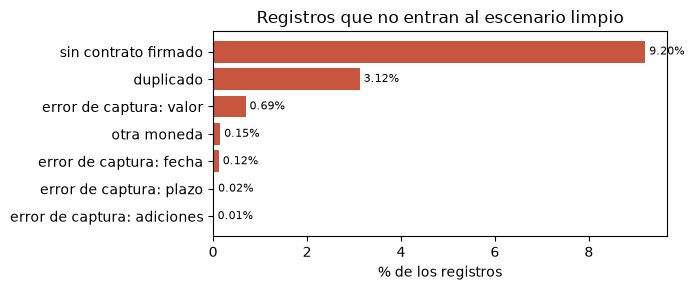

In [15]:
fig, ax = plt.subplots(figsize=(7, 3))
otros = motivos[motivos["motivo_exclusion"] != "(válido: escenario limpio)"]
ax.barh(otros["motivo_exclusion"], otros["porcentaje"], color="#c8553d")
ax.invert_yaxis()
ax.set_xlabel("% de los registros")
ax.set_title("Registros que no entran al escenario limpio")
for i, v in enumerate(otros["porcentaje"]):
    ax.text(v, i, f" {v:.2f}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS / "motivos_exclusion.png", dpi=130)
plt.show()

## 8. Muestras para los modelos

DBSCAN y K-prototypes no existen en Spark: se entrenan con scikit-learn y `kmodes`, que trabajan en memoria. Por eso los entrenamos con **muestras aleatorias de 50.000 registros**:

* **muestra cruda:** de *todos* los registros (incluye duplicados, procesos sin firmar, etc.),
* **muestra limpia:** solo de los registros válidos.

En el notebook 05 aplicamos el modelo limpio a **todos** los contratos válidos usando Spark.

In [16]:
TAMANO_MUESTRA = 50_000
n_limpios = silver.filter(F.col("motivo_exclusion").isNull()).count()

muestra_cruda = (silver.sample(fraction=1.2 * TAMANO_MUESTRA / n_total, seed=42)
                 .limit(TAMANO_MUESTRA).toPandas())
muestra_limpia = (silver.filter(F.col("motivo_exclusion").isNull())
                  .sample(fraction=1.2 * TAMANO_MUESTRA / n_limpios, seed=42)
                  .limit(TAMANO_MUESTRA).toPandas())

muestra_cruda.to_parquet(MUESTRAS / "muestra_cruda.parquet")
muestra_limpia.to_parquet(MUESTRAS / "muestra_limpia.parquet")
print(f"Registros válidos: {n_limpios:,} de {n_total:,} ({100 * n_limpios / n_total:.1f}%)")
print("Muestras guardadas:", len(muestra_cruda), len(muestra_limpia))

Registros válidos: 5,628,310 de 6,492,451 (86.7%)
Muestras guardadas: 50000 50000


## 9. ¿Fue buena idea usar Spark? Comparación con DuckDB

Comparamos el tiempo de una consulta sencilla (contar contratos por modalidad) en tres casos:
1. DuckDB leyendo el CSV,
2. Spark leyendo el CSV,
3. Spark leyendo el Parquet.

In [17]:
import duckdb
duckdb.sql("SET enable_progress_bar = false")

inicio = time.time()
duckdb.sql(f"""SELECT "Modalidad de Contratacion", count(*) FROM read_csv('{CSV}', all_varchar=true)
               GROUP BY 1""").fetchall()
t_duckdb = time.time() - inicio

inicio = time.time()
csv_spark = spark.read.option("header", True).option("multiLine", True).option("escape", '"').csv(str(CSV))
csv_spark.groupBy("Modalidad de Contratacion").count().collect()
t_spark_csv = time.time() - inicio

inicio = time.time()
spark.read.parquet(str(BRONZE)).groupBy("modalidad_de_contratacion").count().collect()
t_spark_parquet = time.time() - inicio

comparacion = pd.DataFrame({
    "motor": ["DuckDB sobre CSV", "Spark sobre CSV (multiLine)", "Spark sobre Parquet"],
    "segundos": [round(t_duckdb, 1), round(t_spark_csv, 1), round(t_spark_parquet, 1)],
    "particiones": ["-", csv_spark.rdd.getNumPartitions(), spark.read.parquet(str(BRONZE)).rdd.getNumPartitions()],
})
comparacion.to_csv(TABLAS / "comparacion_motores.csv", index=False)
comparacion

,motor,segundos,particiones
0,DuckDB sobre CSV,33.3,-
1,Spark sobre CSV (multiLine),140.9,1
2,Spark sobre Parquet,2.2,16


**Interpretación honesta:**

* Para **leer el CSV**, Spark es lento: con `multiLine=True` el archivo no se puede dividir, así que lo lee **una sola tarea** (1 partición). DuckDB es mucho más rápido en ese paso.
* Una vez en **Parquet**, Spark lee en paralelo y es rápido.
* Spark se justifica en los pasos que vienen después de la ingesta:
  - la limpieza (con deduplicación por ventana) sobre datos que no caben en memoria,
  - aplicar los modelos a los 5,6 millones de contratos (notebook 05), que se reparte entre todos los núcleos y escalaría igual en un clúster.

Ver `docs/07_justificacion_pyspark.md`.

In [18]:
spark.stop()